# Prescribed SIP: a hands-on GFS demonstration

Change **code cell 1 — USER SETTINGS**, then select **Restart Kernel → Run All**.
Choose the repository's `.venv` Python kernel. This notebook runs **one** experiment,
not the full simulation framework. Its new target is a teaching example, distinct
from the two frozen targets in the completed paper experiment.

We prescribe first-order inclusion probabilities (FIP) $\pi_i$, create a valid
fixed-size target by random package exchanges, then ask the **original package
optimizer** to reconstruct its second-order inclusion probabilities (SIP).

All probabilities and checks use `float64`. No package source files are changed.
For a first look, leave the small defaults below unchanged.

In [172]:
# ---------------- USER SETTINGS ----------------
POPULATION = "synthetic"       # "synthetic" (exactly N units) or "MU284" (CSV rows)
N = 20                         # For a synthetic large example: 284
n = 5                          # For the large example: 40
FIP_TYPE = "unequal"             # "equal" or "unequal"
SEED = 12345                   # Reproducible population, target, and search seeds
MU284_SIZE_COLUMN = "P75"      # Earlier MU284 experiment's size variable; editable

# Objective-independent target construction
TARGET_EXCHANGES = 2000       # Accepted, distribution-changing package exchanges
TARGET_ALPHA = 0.75            # Exchange mass = alpha * min(two fragment masses)
TARGET_M = 1                   # Partitions requested per target exchange (one exists)
TARGET_CHECK_EVERY = 50         # Checkpoint spacing for target diagnostics

# Reconstruction: the existing GreedyBestFirstSearch.run
GFS_MAX_EVALUATIONS = 100000     # Hard maximum of scored candidates, excluding p0
GFS_FRONTIER_SIZE = 50         # Maximum open-set/frontier size
GFS_EXCHANGE_COEFFICIENT = 0.75
GFS_M = 1                     # Package exchanges/order changes per neighbor
GFS_EXCHANGE_NODES = 10        # Exchange neighbors requested per search iteration
GFS_ORDER_NODES = 2            # Order-change neighbors requested per iteration
GFS_STAGNATION_EVALUATIONS = None  # Stop after this many scores without improvement;
                                  # set to None to disable this observer stop
GFS_RMSE_STOP = 1e-10           # Early recovery threshold (loss is D2, not RMSE)

# Optional additional GFS search (same initial design and target)
RUN_GFS_DIRECTED = True
DIRECTED_MAX_EVALUATIONS = GFS_MAX_EVALUATIONS  # Editable independent ceiling
DIRECTED_BATCH_SIZE = 50  # Score this many exchange directions per batch

# Optional competitors (enumerated CP(2)/oracle automatically disabled when large)
RUN_CP2 = True
RUN_DSD = True
RUN_EXACT_QP = True            # First tries exact SIP feasibility by LP; QP if needed
CP2_MAX_EVALUATIONS = 50000     # CP(2) dual evaluations, a different unit from GFS
CP2_MAX_SECONDS = 60
DSD_MAX_EVALUATIONS = 250      # Random order-fitting trials in a restricted family
EXACT_MAX_SECONDS = 60
ENUMERATION_LIMIT = 50000       # Hard limit on number of enumerated fixed-size samples

# Diagnostics and large-population protection
TRACE_EVERY = 50
PROGRESS_EVERY = 250            # Print concise target/search progress
SHOW_FULL_SUPPORT = False       # Set True for complete p0/p_star tables when N <= 12
BENCHMARK_EVALUATIONS = 100     # Short separate pilot when N >= 100
ALLOW_LONG_RUN = False         # Must become True if estimated GFS runtime > 30 min
# ------------------------------------------------


## 1. Imports and the precision adapter

We import your actual `Population`, `Order`, and `GreedyBestFirstSearch` classes.
The existing small `Float64Design` adapter retains `Design._build`, `Design.exchange`,
and `Design._switch`; it keeps probability extraction in double precision, retains
fragments above $10^{-15}$ instead of $10^{-9}$, preserves its type when copying,
and conditions certainty units out of the original builder before adding them back.
It is a numerical adapter, not a different search algorithm.

`seeded_package` temporarily seeds package-created random generators and restores
random state afterwards. This notebook is serial, so no multiprocessing is involved.
You can inspect the adapter at `prescribed_sip/methods/package_gfs.py`.

In [173]:
import sys
from pathlib import Path
from itertools import combinations
from math import comb, fsum
from time import perf_counter
import inspect

# Works from the repository root or this notebook's directory.
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "graphical_sampling").is_dir()), None)
if REPO is None:
    raise RuntimeError("Open this notebook inside the graphical-sampling repository.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from graphical_sampling import Population, Order, Design
from graphical_sampling.order import Cluster, Zone
from graphical_sampling.search import GreedyBestFirstSearch
from prescribed_sip.methods.package_gfs import Float64Design, seeded_package, extract_support

plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.grid": False})
print("Repository:", REPO)
print("Python:", sys.executable)
print("Search source:", inspect.getsourcefile(GreedyBestFirstSearch.run))
print("Exchange source:", inspect.getsourcefile(Float64Design.exchange))
assert Float64Design.exchange is Design.exchange
assert Float64Design._switch is Design._switch
print("Confirmed: adapter uses the actual package exchange and four-sample split.")


Repository: /home/bardia/projects/graphical-sampling
Python: /home/bardia/projects/graphical-sampling/.venv/bin/python
Search source: /home/bardia/projects/graphical-sampling/graphical_sampling/search/gbfs.py
Exchange source: /home/bardia/projects/graphical-sampling/graphical_sampling/design.py
Confirmed: adapter uses the actual package exchange and four-sample split.


## 2. Construct the population and prescribed FIP

For positive sizes $x_i$, start with $\pi_i=nx_i/\sum_jx_j$. If this exceeds one,
solve $\sum_i\min(cx_i,1)=n$ by bisection. Certainty units have $\pi_i=1$.
Synthetic units sit in their original order on a line; no geography is invented.

**MU284 data detail:** the CSV in this repository has **281 observations**. We use
all actual rows and report `N` accordingly. Set `POPULATION="synthetic"` to obtain
exactly 284 units. `P75` is used for size in
`simulations/abc/scripts/run_abc_mu284_terminal.py`; other historical examples used
other columns, so the choice is explicit and editable.

N=20, n=5, min(pi)=0.17675919, max(pi)=0.32393061, mean(pi)=0.25000000, sum(pi)=5.000000000000


,unit (0-based),x,pi
0,0,0.809135,0.199437
1,1,0.871731,0.214866
2,2,1.208156,0.297789
3,3,1.123378,0.276892
4,4,0.923777,0.227694
5,5,0.882970,0.217636
6,6,1.068816,0.263444
7,7,0.780714,0.192432
8,8,1.120929,0.276289
9,9,1.309262,0.322709


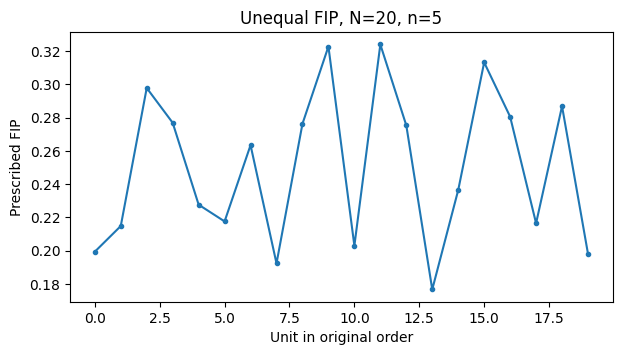

In [174]:
def inclusion_probabilities(x, sample_size):
    x = np.asarray(x, dtype=np.float64)
    if np.any(~np.isfinite(x)) or np.any(x <= 0):
        raise ValueError("Size values must be finite and positive.")
    if not 1 <= sample_size <= len(x):
        raise ValueError("Require 1 <= n <= N.")
    direct = sample_size * x / x.sum()
    if np.max(direct) <= 1:
        return direct
    lower, upper = 0., 1. / float(np.min(x))
    for _ in range(100):
        c = (lower + upper) / 2
        if np.minimum(c * x, 1.).sum() < sample_size:
            lower = c
        else:
            upper = c
    return np.minimum(((lower + upper) / 2) * x, 1.)

rng = np.random.default_rng(SEED)
if POPULATION == "MU284":
    dataset_path = REPO / "simulations/abc/populations/real/MU284.csv"
    population_df = pd.read_csv(dataset_path)
    requested_N = N
    N = len(population_df)
    x = population_df[MU284_SIZE_COLUMN].to_numpy(dtype=np.float64)
    print(f"Loaded {dataset_path}: {N} actual rows (requested N={requested_N}).")
    print("Size column:", MU284_SIZE_COLUMN)
elif POPULATION == "synthetic":
    x = rng.uniform(0.65, 1.35, N).astype(np.float64)
    population_df = pd.DataFrame({"unit": np.arange(N), "x": x})
else:
    raise ValueError('POPULATION must be "synthetic" or "MU284".')

if not isinstance(n, int) or not 1 <= n <= N:
    raise ValueError("n must be an integer between 1 and the actual population size.")
if FIP_TYPE == "equal":
    pi = np.full(N, n / N, dtype=np.float64)
elif FIP_TYPE == "unequal":
    pi = inclusion_probabilities(x, n)
else:
    raise ValueError('FIP_TYPE must be "equal" or "unequal".')
coords = np.column_stack([np.linspace(0., 1., N), np.zeros(N)])
pair_indices = np.triu_indices(N, 1)
number_of_pairs = comb(N, 2)
assert abs(pi.sum() - n) < 1e-10
print(f"N={N}, n={n}, min(pi)={pi.min():.8f}, max(pi)={pi.max():.8f}, "
      f"mean(pi)={pi.mean():.8f}, sum(pi)={pi.sum():.12f}")
display(pd.DataFrame({"unit (0-based)": np.arange(N), "x": x, "pi": pi}))
plt.plot(np.arange(N), pi, ".-")
plt.xlabel("Unit in original order"); plt.ylabel("Prescribed FIP")
plt.title(f"{FIP_TYPE.capitalize()} FIP, N={N}, n={n}"); plt.show()


## 3. Small, visible probability and SIP helpers

If $p(s)$ is the probability of sample $s$, then
$\pi_i=\sum_s p(s)I_i(s)$ and $\pi_{ij}=\sum_s p(s)I_i(s)I_j(s)$.
`compute_SIP` implements this formula with a sparse indicator matrix, using only
the **current support**, not all $\binom{N}{n}$ possible samples. It therefore works
at 284 units too. The diagonal of the matrix is FIP.

`validate_design` independently recomputes these sums sample by sample. Nothing is
renormalized to conceal mass or FIP error. Standardized dependence is computed
only for pairs without certainty units; their zero-variance correlation is undefined.

In [175]:
def distribution(design):
    """Aggregate duplicate sample fragments without altering the design."""
    if hasattr(design, "mass"):   # Enumerated competitors return a Support object.
        return dict(design.mass)
    fragments = {}
    for heap in design._heaps:
        for sample in heap:
            key = tuple(sorted(sample.ids))
            fragments.setdefault(key, []).append(float(sample.prob))
    return {key: fsum(parts) for key, parts in fragments.items()}


def compute_SIP(design):
    mass = distribution(design)
    size = design.pop.N if hasattr(design, "pop") else design.N
    samples = list(mass)
    probabilities = np.array(list(mass.values()), dtype=np.float64)
    row = np.array([i for sample in samples for i in sample], dtype=int)
    col = np.repeat(np.arange(len(samples)), [len(s) for s in samples])
    indicators = sparse.csr_matrix((np.ones(len(row)), (row, col)),
                                   shape=(size, len(samples)))
    return (indicators.multiply(probabilities) @ indicators.T).toarray()


def entropy(design):
    p = np.array(list(distribution(design).values()), dtype=np.float64)
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))   # Natural logarithms: entropy in nats.


def validate_design(design, expected_pi):
    size, sample_size = len(expected_pi), int(round(sum(expected_pi)))
    mass = distribution(design)
    independent = np.zeros((size, size), dtype=np.float64)
    for sample, probability in mass.items():
        if probability > 0 and len(sample) != sample_size:
            raise ValueError("A positive-probability sample has the wrong size.")
        independent[np.ix_(sample, sample)] += probability
    computed = compute_SIP(design)
    errors = {"FIP max error": float(np.max(abs(np.diag(independent) - expected_pi))),
              "Probability sum error": abs(fsum(mass.values()) - 1.),
              "Min probability": min(mass.values()),
              "SIP recomputation error": float(np.max(abs(computed - independent))),
              "Fixed-size row error": float(np.max(abs(independent.sum(axis=1)
                                                       - sample_size * expected_pi))),
              "Pair-total error": abs(independent[np.triu_indices(size, 1)].sum()
                                       - comb(sample_size, 2))}
    if errors["Min probability"] < -1e-12 or any(
        value > 1e-9 for name, value in errors.items() if name != "Min probability"
    ):
        raise ValueError(f"Design validation failed: {errors}")
    return errors


def sip_errors(Pi, target):
    difference = (Pi - target)[np.triu_indices(len(Pi), 1)]
    D2 = float(difference @ difference)
    return {"D2": D2, "RMSE": float(np.sqrt(D2 / len(difference))),
            "Max SIP error": float(np.max(abs(difference)))}


def dependence_distance(Pi, reference):
    i, j = np.triu_indices(len(pi), 1)
    denominator = np.sqrt(pi[i] * (1 - pi[i]) * pi[j] * (1 - pi[j]))
    valid = denominator > 0
    if not np.any(valid):
        return np.nan
    # pi_i*pi_j cancels when subtracting the two standardized dependences.
    difference = ((Pi - reference)[i[valid], j[valid]] / denominator[valid])
    return float(np.sqrt(np.mean(difference ** 2)))


def enumeration_allowed(size, sample_size):
    return size < 100 and comb(size, sample_size) <= ENUMERATION_LIMIT


def show_support(design, label):
    print(f"{label}: support={len(distribution(design))}, entropy={entropy(design):.8f}")
    if SHOW_FULL_SUPPORT and N <= 12:
        with pd.option_context("display.max_rows", None):
            display(pd.DataFrame([{"sample (0-based)": sample, "probability": p}
                                   for sample, p in sorted(distribution(design).items())]))


## 4. Build the original simple GFS design

One cluster, one zone, original unit order, and one unsplit segment per unit.
The build below uses the package's order representation and design builder.
Setting `pop._n` avoids truncating a floating sum such as 3.9999999999999996 to 3.

In [176]:
pop = Population(coords=coords, inclusions=pi, variable=x, n=None)
pop._n = n
zone = Zone(_shares=np.ones(N), _indices=np.arange(N), sort=list(range(N)))
order = Order(pop)
order.clusters = [Cluster(label=0, zones=[zone])]
order.num_zones = 1
order.num_splits = 1
order._build_order(1)
with seeded_package(SEED):
    p0 = Float64Design.from_order(pop, order)
Pi0 = compute_SIP(p0)
show_support(p0, "p0")
print("Independent initial checks:", validate_design(p0, pi))


p0: support=20, entropy=2.50509282
Independent initial checks: {'FIP max error': 5.551115123125783e-16, 'Probability sum error': 0.0, 'Min probability': 0.0017068677700202706, 'SIP recomputation error': 0.0, 'Fixed-size row error': 2.7755575615628914e-15, 'Pair-total error': np.float64(0.0)}


## 5. Create a target using random package segment exchanges

There is **no reconstruction criterion in this cell**. In a package exchange,
two samples $a,b$ trade one unit each: $a',b'$. Mass
$\epsilon=\alpha\min[p(a),p(b)]$ is removed from $a,b$ and added to $a',b'$.
The sum of the two indicator vectors is unchanged, so FIP and sample size are
preserved. We call your actual `Design.exchange`, with random fragment selection.

We count **accepted exchanges that change the aggregated sample distribution**
(total mass movement $>10^{-14}$). Identical fragments or a swap that just exchanges
sample labels do not count. This convention differs from the earlier paper walk,
which included valid null transactions. `TARGET_M` requests partitions; only one
partition exists here, so its effective value is one.

The target here is the **endpoint after exactly TARGET_EXCHANGES accepted moves**.
It is not automatically replaced by the most separated snapshot. Inspect the
plots and change the setting yourself. If no nontrivial exchanges are possible,
the cell explains the issue rather than looping forever.

In [177]:
if not isinstance(TARGET_EXCHANGES, int) or TARGET_EXCHANGES < 0:
    raise ValueError("TARGET_EXCHANGES must be a nonnegative integer.")
if not 0 < TARGET_ALPHA <= 1 or not isinstance(TARGET_M, int) or TARGET_M < 1:
    raise ValueError("Require 0 < TARGET_ALPHA <= 1 and positive integer TARGET_M.")
if min(TARGET_CHECK_EVERY, PROGRESS_EVERY, TRACE_EVERY) < 1:
    raise ValueError("Diagnostic intervals must be positive.")

current_design = p0.copy()
accepted_exchanges = 0
attempted_exchanges = 0
target_trace = []
target_started = perf_counter()

def target_checkpoint():
    current_Pi = compute_SIP(current_design)
    target_trace.append({"exchanges": accepted_exchanges,
                         "entropy": entropy(current_design),
                         "support": len(distribution(current_design)),
                         "effective support": np.exp(entropy(current_design)),
                         "RMSE from p0": sip_errors(current_Pi, Pi0)["RMSE"],
                         "d_rho": dependence_distance(current_Pi, Pi0),
                         "seconds": perf_counter() - target_started})

target_checkpoint()
with seeded_package(SEED + 1):
    while accepted_exchanges < TARGET_EXCHANGES:
        if N >= 100 and not ALLOW_LONG_RUN and perf_counter() - target_started > 1800:
            raise RuntimeError("Target construction reached the 30-minute safety limit. "
                               "Reduce TARGET_EXCHANGES or explicitly set ALLOW_LONG_RUN=True.")
        attempted_exchanges += 1
        if attempted_exchanges > max(1000, 100 * TARGET_EXCHANGES):
            raise RuntimeError("Too few nontrivial valid exchanges. Reduce the requested "
                               "count or inspect p0, n, pi and TARGET_ALPHA.")
        proposal = current_design.copy()
        before = distribution(current_design)
        # THIS IS YOUR PACKAGE'S FIXED-SIZE SEGMENT-EXCHANGE OPERATION.
        proposal.exchange(partitions=TARGET_M, pull_strategy="random",
                          exchange_coef=TARGET_ALPHA)
        proposal.merge_identical()   # Combine fragments; same sampling distribution.
        after = distribution(proposal)
        moved_mass = fsum(abs(after.get(s, 0.) - before.get(s, 0.))
                          for s in before.keys() | after.keys())
        if moved_mass <= 1e-14:
            continue
        current_design = proposal
        accepted_exchanges += 1
        if N >= 100 and accepted_exchanges == 20 and not ALLOW_LONG_RUN:
            projected = 3 * (perf_counter() - target_started) / 20 * TARGET_EXCHANGES
            print(f"Target pilot: protected endpoint estimate {projected / 60:.2f} min.")
            if projected > 1800:
                raise RuntimeError("Long target walk blocked. Reduce TARGET_EXCHANGES "
                                   "or explicitly set ALLOW_LONG_RUN=True and rerun.")
        if accepted_exchanges % TARGET_CHECK_EVERY == 0:
            validate_design(current_design, pi)
            target_checkpoint()
        if accepted_exchanges % PROGRESS_EVERY == 0:
            print(f"Target: {accepted_exchanges}/{TARGET_EXCHANGES} accepted exchanges; "
                  f"{perf_counter() - target_started:.1f} s", flush=True)
if target_trace[-1]["exchanges"] != accepted_exchanges:
    target_checkpoint()

# The target is visibly frozen here, from the current endpoint:
p_star = current_design
Pi_star = compute_SIP(p_star)
target_runtime = perf_counter() - target_started
target_history = pd.DataFrame(target_trace)
print(f"Target created: {accepted_exchanges} accepted / {attempted_exchanges} attempted; "
      f"TARGET_EXCHANGES={TARGET_EXCHANGES}; {target_runtime:.2f} s")
print("Independent target checks:", validate_design(p_star, pi))
show_support(p_star, "p_star")


Target: 250/2000 accepted exchanges; 0.3 s
Target: 500/2000 accepted exchanges; 1.2 s
Target: 750/2000 accepted exchanges; 2.6 s
Target: 1000/2000 accepted exchanges; 4.7 s
Target: 1250/2000 accepted exchanges; 7.4 s
Target: 1500/2000 accepted exchanges; 10.7 s
Target: 1750/2000 accepted exchanges; 14.8 s
Target: 2000/2000 accepted exchanges; 19.4 s
Target created: 2000 accepted / 2029 attempted; TARGET_EXCHANGES=2000; 19.42 s
Independent target checks: {'FIP max error': 1.1102230246251565e-15, 'Probability sum error': 0.0, 'Min probability': 5.594904259438699e-15, 'SIP recomputation error': 0.0, 'Fixed-size row error': 2.55351295663786e-15, 'Pair-total error': np.float64(1.7763568394002505e-15)}
p_star: support=3060, entropy=3.47702400


## 6. Inspect how different the target became

Heatmaps include FIP on the diagonal. Differences, histograms, RMSE, and maximum
pair errors use only unordered off-diagonal pairs. A larger exchange count does
not guarantee a monotonically increasing distance from the starting design.

RMSE(Pi0, Pi_star) = 0.03540616401
Maximum SIP difference = 0.1012761387
Median SIP difference = 0.006825404553
d_rho = 0.1859972466
Entropy initial/target = 2.50509282 / 3.47702400
Support initial/target = 20 / 3060


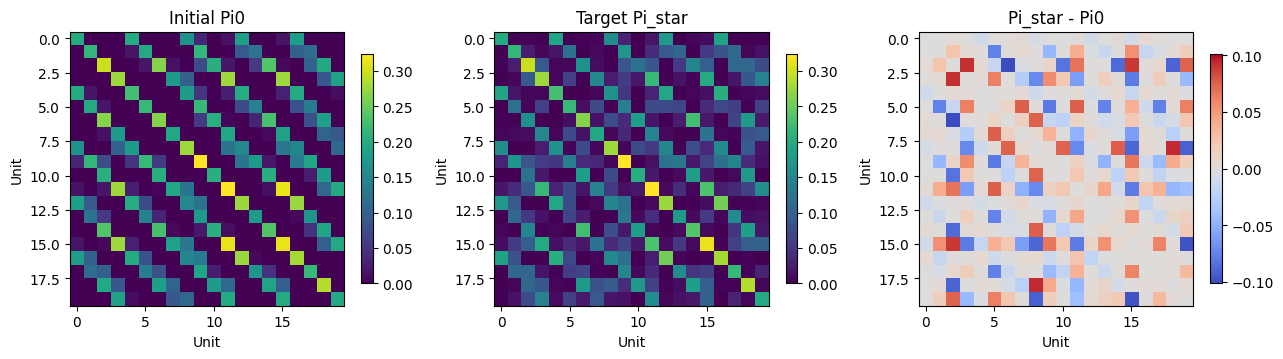

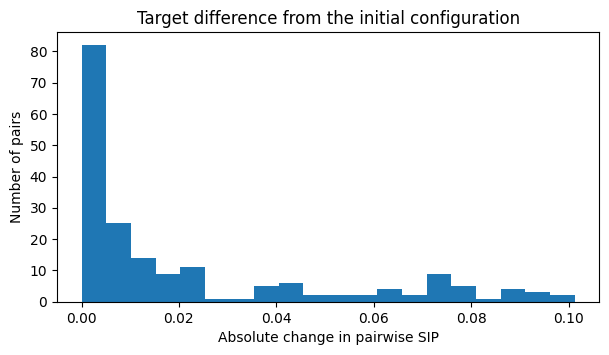

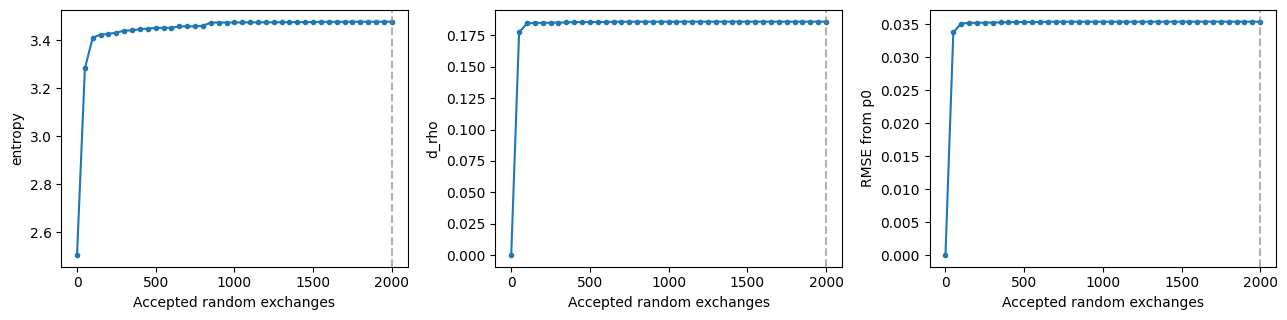

In [178]:
initial_to_target = sip_errors(Pi0, Pi_star)
baseline_rmse = initial_to_target["RMSE"]
pair_difference = abs((Pi_star - Pi0)[pair_indices])
print(f"RMSE(Pi0, Pi_star) = {baseline_rmse:.10g}")
print(f"Maximum SIP difference = {pair_difference.max():.10g}")
print(f"Median SIP difference = {np.median(pair_difference):.10g}")
print(f"d_rho = {dependence_distance(Pi_star, Pi0):.10g}")
print(f"Entropy initial/target = {entropy(p0):.8f} / {entropy(p_star):.8f}")
print(f"Support initial/target = {len(distribution(p0))} / {len(distribution(p_star))}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
maximum = max(Pi0.max(), Pi_star.max())
for ax, matrix, label in zip(axes[:2], [Pi0, Pi_star], ["Initial Pi0", "Target Pi_star"]):
    im = ax.imshow(matrix, vmin=0, vmax=maximum, cmap="viridis")
    ax.set_title(label); fig.colorbar(im, ax=ax, shrink=.8)
difference = Pi_star - Pi0
limit = max(float(abs(difference).max()), 1e-15)
im = axes[2].imshow(difference, vmin=-limit, vmax=limit, cmap="coolwarm")
axes[2].set_title("Pi_star - Pi0"); fig.colorbar(im, ax=axes[2], shrink=.8)
for ax in axes:
    ax.set_xlabel("Unit"); ax.set_ylabel("Unit")
plt.tight_layout(); plt.show()

plt.hist(pair_difference, bins=20)
plt.xlabel("Absolute change in pairwise SIP"); plt.ylabel("Number of pairs")
plt.title("Target difference from the initial configuration"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, column in zip(axes, ["entropy", "d_rho", "RMSE from p0"]):
    ax.plot(target_history["exchanges"], target_history[column], ".-")
    ax.set_xlabel("Accepted random exchanges"); ax.set_ylabel(column)
    ax.axvline(TARGET_EXCHANGES, ls="--", color="grey", alpha=.6)
plt.tight_layout(); plt.show()


## 7. Scoring and observing your existing GFS search

We minimize $D_2=\sum_{i<j}(\pi_{ij}-\pi^*_{ij})^2$, with
$\mathrm{RMSE}=\sqrt{D_2/\binom{N}{2}}$. Candidate scoring recomputes SIP from support.
The optimizer receives `p0`, prescribed FIP, and `Pi_star`; **never `p_star`**.

The function below is a budget/progress wrapper, **not an optimizer**. Its central
call is the unmodified `search.run`, implemented by your
`GreedyBestFirstSearch.run`. That implementation generates order neighbors and
exchange neighbors; the latter call the existing `Design.exchange`.

The package rounds **D2 incumbent comparisons to nine decimals**, while its frontier
uses raw scores. We preserve this behavior. Observed best candidates use the same
rounded comparison. If a strict budget interrupts scoring in the middle of a batch,
we return the best *fully evaluated* candidate, including that partial batch, and
report the package reservoir separately. This does not alter candidate generation.
Early stopping and stagnation can use fewer than the requested maximum evaluations.

**Serial tracking requirement:** this notebook wrapper requires `n_jobs=1`. With a process backend, each worker would mutate its own copy of the evaluation counter, incumbent and trace. The optimizer receives scores, but the notebook could report the wrong incumbent or bypass its candidate budget. `run_gfs` rejects parallel scoring before launching workers; a parallel adapter must collect scores and update tracking in the parent process.

In [179]:
class SearchBudgetReached(RuntimeError):
    pass


def recovery_percent(rmse):
    if baseline_rmse == 0:
        return 100. if rmse == 0 else np.nan  # Relative recovery is otherwise undefined.
    return 100. * (1. - rmse / baseline_rmse)


def runtime_permitted(estimated_seconds, allow_long_run):
    return allow_long_run or estimated_seconds <= 30 * 60


search_parameters = dict(
    max_open_set_size=GFS_FRONTIER_SIZE, top_k=1,
    num_new_order_nodes=GFS_ORDER_NODES,
    num_new_exchange_nodes=GFS_EXCHANGE_NODES,
    num_clusters_range=(1, 1), num_zones_range=(1, 1),
    num_changes_range=(GFS_M, GFS_M), num_zone_changes=0,
    pull_strategy="default", exchange_coef=GFS_EXCHANGE_COEFFICIENT,
    num_explore=1, n_jobs=1, backtrack_depth=0,
    stagnation_limit=100, output_mode="silent",
)
print("Actual package parameters:", search_parameters)
print(f"M={GFS_M}; exchange alpha={GFS_EXCHANGE_COEFFICIENT}; "
      f"frontier={GFS_FRONTIER_SIZE}; exchange/order branches="
      f"{GFS_EXCHANGE_NODES}/{GFS_ORDER_NODES}")
print(f"Stopping: <= {GFS_MAX_EVALUATIONS} scored candidates, "
      f"RMSE < {GFS_RMSE_STOP}, frontier exhaustion, or "
      f"{GFS_STAGNATION_EVALUATIONS} candidates without rounded incumbent improvement.")
print("D2 incumbent comparisons: round(score, 9); raw-score frontier ordering.")
print("Package stagnation_limit=100 triggers its shock/backtracking logic; "
      "the separate scored-candidate stagnation setting is an observer stop.")
print("Candidate exchanges: GreedyBestFirstSearch._apply_exchange -> Design.exchange.")


def run_gfs(max_evaluations, verbose=True, max_seconds=None):
    if search_parameters.get("n_jobs", 1) != 1:
        raise ValueError(
            "This notebook's progress, best-result tracking and candidate budget require "
            "n_jobs=1. Set n_jobs=1 in search_parameters and rerun this definition cell. "
            "Parallel scoring needs a separate adapter with tracking in the parent process."
        )
    if max_evaluations < 1:
        raise ValueError("GFS_MAX_EVALUATIONS must be positive.")
    if GFS_M < 1 or GFS_FRONTIER_SIZE < 1 or not 0 < GFS_EXCHANGE_COEFFICIENT <= 1:
        raise ValueError("Require positive M/frontier and 0 < exchange coefficient <= 1.")
    started = perf_counter()
    count, last_improvement = 0, 0
    best_design, best_loss = None, None
    trace = []
    status = "package search finished"

    def record():
        rmse = np.sqrt(best_loss / number_of_pairs)
        row = {"evaluations": count, "D2": best_loss, "RMSE": rmse,
               "Recovery %": recovery_percent(rmse), "runtime": perf_counter() - started}
        if trace and trace[-1]["evaluations"] == count:
            trace[-1] = row
        else:
            trace.append(row)

    def criterion(design):
        nonlocal count, best_design, best_loss, last_improvement
        if design is not start_design:
            if count >= max_evaluations:
                raise SearchBudgetReached("candidate budget reached")
            if max_seconds is not None and perf_counter() - started >= max_seconds:
                raise SearchBudgetReached("30-minute safety time limit reached")
            count += 1
        Pi = compute_SIP(design)
        differences = (Pi - Pi_star)[pair_indices]
        D2 = float(differences @ differences)
        if best_loss is None or round(D2, 9) < round(best_loss, 9):
            best_design, best_loss, last_improvement = design, D2, count
        if count % TRACE_EVERY == 0:
            record()
        if verbose and count > 0 and count % PROGRESS_EVERY == 0:
            print(f"GFS: {count}/{max_evaluations} scores; "
                  f"best RMSE={np.sqrt(best_loss / number_of_pairs):.6g}; "
                  f"{perf_counter() - started:.1f} s", flush=True)
        return D2

    def progress(search, iteration):
        if (GFS_STAGNATION_EVALUATIONS is not None
                and count - last_improvement >= GFS_STAGNATION_EVALUATIONS):
            raise SearchBudgetReached("scored-candidate stagnation limit reached")

    with seeded_package(SEED + 2):
        start_design = p0.copy()   # RESET: always reconstruct from p0.
        search = GreedyBestFirstSearch([start_design], criterion)
        try:
            # YOUR ACTUAL OPTIMIZER: no rewritten search or high-precision variant.
            search.run(
                max_iterations=max(1000, max_evaluations * 2),
                **search_parameters,
                stop_when=lambda design, D2: D2 < number_of_pairs * GFS_RMSE_STOP ** 2,
                progress_callback=progress,
            )
        except SearchBudgetReached as error:
            status = str(error)
    record()
    final_Pi = compute_SIP(best_design)
    validation = validate_design(best_design, pi)
    final_metrics = sip_errors(final_Pi, Pi_star)
    return {"design": best_design, "Pi": final_Pi, **final_metrics,
            "Recovery %": recovery_percent(final_metrics["RMSE"]),
            "evaluations": count, "runtime": perf_counter() - started,
            "trace": pd.DataFrame(trace), "validation": validation, "status": status,
            "package reservoir RMSE": np.sqrt(search.reservoir_val / number_of_pairs)}


Actual package parameters: {'max_open_set_size': 50, 'top_k': 1, 'num_new_order_nodes': 2, 'num_new_exchange_nodes': 10, 'num_clusters_range': (1, 1), 'num_zones_range': (1, 1), 'num_changes_range': (1, 1), 'num_zone_changes': 0, 'pull_strategy': 'default', 'exchange_coef': 0.75, 'num_explore': 1, 'n_jobs': 1, 'backtrack_depth': 0, 'stagnation_limit': 100, 'output_mode': 'silent'}
M=1; exchange alpha=0.75; frontier=50; exchange/order branches=10/2
Stopping: <= 100000 scored candidates, RMSE < 1e-10, frontier exhaustion, or None candidates without rounded incumbent improvement.
D2 incumbent comparisons: round(score, 9); raw-score frontier ordering.
Package stagnation_limit=100 triggers its shock/backtracking logic; the separate scored-candidate stagnation setting is an observer stop.
Candidate exchanges: GreedyBestFirstSearch._apply_exchange -> Design.exchange.


## 8. Large-population speed pilot and explicit opt-in

Only when `N >= 100`, run a short, separately counted GFS pilot. It is discarded;
the real search resets to `p0` with the same search seed. We show a raw speed estimate
and apply a threefold margin to allow for growing support and changing costs.
This is an estimate, not a guarantee. If the protected estimate exceeds 30 minutes,
the main search is **skipped** until `ALLOW_LONG_RUN=True`. Even an underestimated
large run stops after 30 minutes unless you explicitly opt in.

In [180]:
run_reconstruction = True
if N >= 100:
    pilot = run_gfs(min(BENCHMARK_EVALUATIONS, GFS_MAX_EVALUATIONS), verbose=False,
                    max_seconds=None if ALLOW_LONG_RUN else 30 * 60)
    seconds_per_evaluation = pilot["runtime"] / max(pilot["evaluations"], 1)
    print(f"Pilot: {pilot['evaluations']} candidates in {pilot['runtime']:.2f} s; "
          f"seconds / 1000 evaluations = {1000 * seconds_per_evaluation:.2f}")
    for budget in (5000, 20000, 100000):
        print(f"{budget:,} evaluations: {budget * seconds_per_evaluation / 60:.2f} min "
              f"raw; {3 * budget * seconds_per_evaluation / 60:.2f} min with margin")
    estimated_seconds = 3 * seconds_per_evaluation * GFS_MAX_EVALUATIONS
    run_reconstruction = runtime_permitted(estimated_seconds, ALLOW_LONG_RUN)
    if not run_reconstruction:
        print("\n*** LONG GFS RUN BLOCKED ***\nEstimated protected runtime exceeds 30 minutes. "
              "Set ALLOW_LONG_RUN=True in USER SETTINGS and rerun from the start "
              "only if you intend this computation.")
else:
    print("Small population: no large-population pilot needed.")


Small population: no large-population pilot needed.


## 9. Reconstruct and inspect convergence

Recovery is $100(1-\mathrm{RMSE}/\mathrm{RMSE}_0)$: zero is the starting error,
100 is exact recovery, and negative values are worse than the initial design.
The final result is the observed best incumbent. A plateau does not prove local
optimality; this is a finite random search. These plots describe this single run.

GFS: 250/100000 scores; best RMSE=0.0258042; 0.2 s
GFS: 500/100000 scores; best RMSE=0.0245923; 0.3 s
GFS: 750/100000 scores; best RMSE=0.0229457; 0.5 s
GFS: 1000/100000 scores; best RMSE=0.0228326; 0.8 s
GFS: 1250/100000 scores; best RMSE=0.0228326; 1.1 s
GFS: 1500/100000 scores; best RMSE=0.0228306; 1.4 s
GFS: 1750/100000 scores; best RMSE=0.0223614; 1.7 s
GFS: 2000/100000 scores; best RMSE=0.0223493; 2.2 s
GFS: 2250/100000 scores; best RMSE=0.0222254; 2.6 s
GFS: 2500/100000 scores; best RMSE=0.0215234; 3.0 s
GFS: 2750/100000 scores; best RMSE=0.0214822; 3.5 s
GFS: 3000/100000 scores; best RMSE=0.0211647; 4.0 s
GFS: 3250/100000 scores; best RMSE=0.0211615; 4.5 s
GFS: 3500/100000 scores; best RMSE=0.0211268; 5.1 s
GFS: 3750/100000 scores; best RMSE=0.0211268; 5.7 s
GFS: 4000/100000 scores; best RMSE=0.0211268; 6.4 s
GFS: 4250/100000 scores; best RMSE=0.0211268; 7.0 s
GFS: 4500/100000 scores; best RMSE=0.0211268; 7.7 s
GFS: 4750/100000 scores; best RMSE=0.0211268; 8.3 s
GFS: 5000/10000

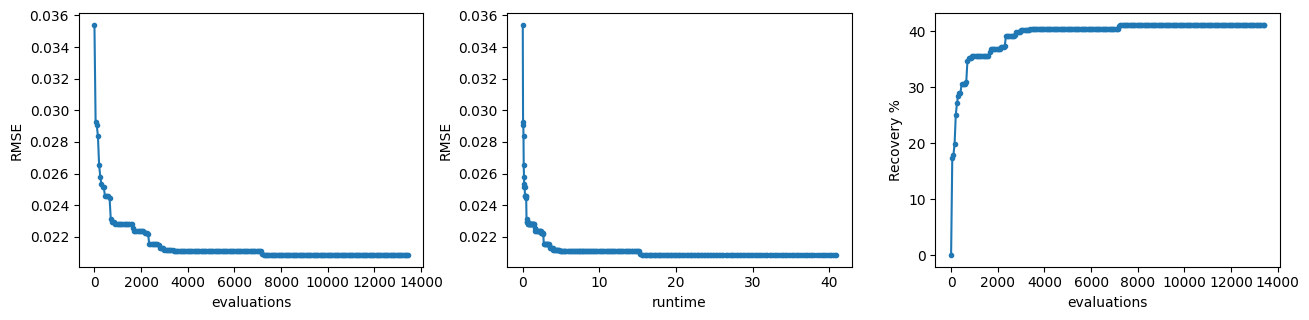

In [181]:
gfs_result = None
if run_reconstruction:
    gfs_result = run_gfs(GFS_MAX_EVALUATIONS,
                         max_seconds=1800 if N >= 100 and not ALLOW_LONG_RUN else None)
    print(f"Starting RMSE: {baseline_rmse:.10g}")
    print(f"Final/best observed RMSE: {gfs_result['RMSE']:.10g}")
    print(f"Final/best Recovery: {gfs_result['Recovery %']:.6f}%")
    print(f"Package reservoir RMSE: {gfs_result['package reservoir RMSE']:.10g}")
    print(f"Evaluations: {gfs_result['evaluations']}/{GFS_MAX_EVALUATIONS}; "
          f"runtime: {gfs_result['runtime']:.2f} s; stop: {gfs_result['status']}")
    print("Independent reconstructed-design checks:", gfs_result["validation"])
    convergence = gfs_result["trace"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    for ax, x_column, y_column in zip(axes,
            ["evaluations", "runtime", "evaluations"], ["RMSE", "RMSE", "Recovery %"]):
        ax.plot(convergence[x_column], convergence[y_column], ".-")
        ax.set_xlabel(x_column); ax.set_ylabel(y_column)
    plt.tight_layout(); plt.show()
else:
    print("GFS reconstruction skipped by the large-run guard.")


## 10. Optional GFS-Directed: use pair errors to guide exchanges

**GFS-Directed had the lowest median RMSE among the GFS searches in the earlier
27-case diagnostic study. That is not a universal ranking.** Here we compare it
with your Original GFS on this notebook's same frozen target, from the same `p0`.

This is the existing **additional search** in
`prescribed_sip/methods/exchange_search.py`, not `GreedyBestFirstSearch.run`.
It represents the same FIP-preserving four-sample mass exchange algebraically
with `Support.exchange`; it does not call `Design.exchange` or its fixed alpha.
Your original package optimizer above remains the primary method.

It selects a pair among the 50 largest absolute residuals (or all pairs if fewer),
constructs an exchange that can move that pair toward its target, and evaluates
**all affected pairs**. When no directed candidate can be formed, it falls back
to a random valid exchange. It scores a batch and accepts its best improving move.

Let $r_{ij}=\widehat\pi_{ij}-\pi^*_{ij}$ and let $c_{ij}$ be the SIP change per unit
of exchanged mass. With $A=\sum_{i<j}r_{ij}c_{ij}$ and
$B=\sum_{i<j}c_{ij}^2$, the exact loss along this exchange is

$$D_2(\epsilon)=D_2(0)+2A\epsilon+B\epsilon^2.$$

The selected mass is $\epsilon=\mathrm{clip}(-A/B,0,\min[p(a),p(b)])$ when $B>0$,
and zero otherwise. Thus the amount is fitted to the target, while preserving FIP,
probability mass, and sample size. It uses raw float64 loss, with no nine-decimal
comparison rounding, a different search policy, and no frontier.

`DIRECTED_MAX_EVALUATIONS` defaults to the Original GFS candidate ceiling. Both
receive only prescribed FIP and target SIP, not `p_star`. Counts represent scored
exchange directions for Directed and scored designs for Original GFS. This is
one-run evidence, not a repeated statistical comparison. Directed checkpoints use
the implementation's existing geometrically spaced monitor plus its final record.

Starting GFS-Directed: <= 100,000 scored directions, batch=50, optimal exchange mass, one start.
GFS-Directed RMSE=0.0001530137142; Recovery=99.57%; 100,000 evaluations; 12.62 s.
Directed status: completed 
Independent Directed checks: {'FIP max error': 5.828670879282072e-16, 'Probability sum error': 0.0, 'Min probability': 4.8076515566987816e-08, 'SIP recomputation error': 0.0, 'Fixed-size row error': 2.886579864025407e-15, 'Pair-total error': np.float64(1.7763568394002505e-15)}
Maximum recorded incremental SIP discrepancy: 3.0531133177191805e-16


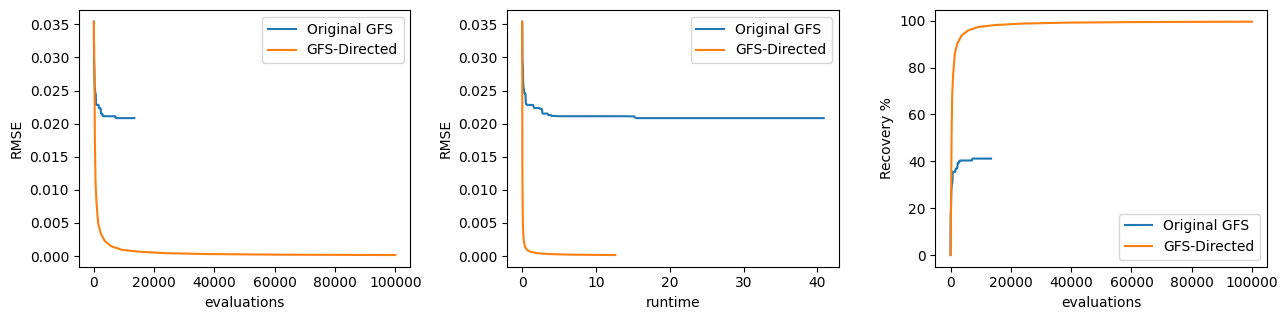

In [182]:
directed_result = None
directed_convergence = pd.DataFrame()
if RUN_GFS_DIRECTED:
    from prescribed_sip.methods.exchange_search import run_exchange
    from prescribed_sip.core.objective import PairObjective

    def run_directed(evaluations):
        # Separate search; fresh p0 support and criterion for every run or pilot.
        return run_exchange(
            initial=extract_support(p0), objective=PairObjective(N, Pi_star), pi=pi,
            seed=SEED + 4, evaluations=evaluations,
            seconds=float("inf") if ALLOW_LONG_RUN else 1800.,
            method="GFS-Directed", batch=DIRECTED_BATCH_SIZE, epsilon="optimal",
        )

    if DIRECTED_MAX_EVALUATIONS < 1 or DIRECTED_BATCH_SIZE < 1:
        raise ValueError("Directed evaluation budget and batch size must be positive.")
    run_directed_full = True
    if N >= 100:
        directed_pilot = run_directed(min(BENCHMARK_EVALUATIONS, DIRECTED_MAX_EVALUATIONS))
        directed_speed = directed_pilot.runtime_seconds / max(directed_pilot.candidate_moves, 1)
        directed_estimate = 3 * directed_speed * DIRECTED_MAX_EVALUATIONS
        print(f"Directed pilot: {1000 * directed_speed:.2f} s / 1000 evaluations; "
              f"protected full-run estimate {directed_estimate / 60:.2f} min.")
        run_directed_full = runtime_permitted(directed_estimate, ALLOW_LONG_RUN)
    if run_directed_full:
        print(f"Starting GFS-Directed: <= {DIRECTED_MAX_EVALUATIONS:,} scored directions, "
              f"batch={DIRECTED_BATCH_SIZE}, optimal exchange mass, one start.", flush=True)
        directed_result = run_directed(DIRECTED_MAX_EVALUATIONS)
        if directed_result.status == "numerical_failure":
            raise RuntimeError(directed_result.failure_reason)
        directed_checks = validate_design(directed_result.support, pi)
        directed_convergence = pd.DataFrame(directed_result.checkpoints)
        directed_convergence["evaluations"] = directed_convergence["candidate_moves"]
        directed_convergence["runtime"] = directed_convergence["runtime_seconds"]
        directed_convergence["D2"] = directed_convergence["incumbent_D2"]
        directed_convergence["RMSE"] = directed_convergence["incumbent_target_RMSE2"]
        directed_convergence["Recovery %"] = directed_convergence["RMSE"].map(recovery_percent)
        print(f"GFS-Directed RMSE={directed_result.final['target_RMSE2']:.10g}; "
              f"Recovery={recovery_percent(directed_result.final['target_RMSE2']):.2f}%; "
              f"{directed_result.candidate_moves:,} evaluations; "
              f"{directed_result.runtime_seconds:.2f} s.")
        print("Directed status:", directed_result.status, directed_result.failure_reason)
        print("Independent Directed checks:", directed_checks)
        print("Maximum recorded incremental SIP discrepancy:",
              directed_result.validation["max_SIP_incremental_error"])
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
        traces = [("GFS-Directed", directed_convergence)]
        if gfs_result is not None:
            traces.insert(0, ("Original GFS", gfs_result["trace"]))
        for ax, x_column, y_column in zip(axes,
                ["evaluations", "runtime", "evaluations"], ["RMSE", "RMSE", "Recovery %"]):
            for method, history in traces:
                ax.plot(history[x_column], history[y_column], label=method)
            ax.set_xlabel(x_column); ax.set_ylabel(y_column); ax.legend()
        plt.tight_layout(); plt.show()
    else:
        print("*** LONG DIRECTED RUN BLOCKED *** Set ALLOW_LONG_RUN=True only "
              "if you intend a Directed run estimated above 30 minutes.")
else:
    print("GFS-Directed skipped by USER SETTINGS.")


## 11. Optional CP(2): existing enumerated implementation

The repository implementation fits the fixed-size exponential family
$p(s)\propto\exp(\sum_i a_iI_i(s)+\sum_{i<j}b_{ij}I_i(s)I_j(s))$ using an exact
partition function, a dual L-BFGS fit, and a final Newton FIP tilt. For $n>1$,
first-order terms can be absorbed into pair terms. This is **enumerated CP(2)
calibration**, not a reproduction of Bondesson's iterative/Gibbs program.

Enumeration is disabled at `N >= 100` or when the sample count exceeds the settings
limit. Competitors receive `pi` and `Pi_star`, not target sample probabilities.

In [183]:
method_results = []

def summary_row(method, design, runtime=0., evaluations=0, Pi=None):
    metrics = sip_errors(compute_SIP(design) if Pi is None else Pi, Pi_star)
    checks = validate_design(design, pi)
    return {"Method": method, "RMSE": metrics["RMSE"],
            "Recovery %": recovery_percent(metrics["RMSE"]),
            "Max SIP error": metrics["Max SIP error"], "Runtime": runtime,
            "Evaluations": evaluations, "FIP max error": checks["FIP max error"],
            "Support size": len(distribution(design)), "Entropy": entropy(design)}

method_results.append(summary_row("Initial", p0))
if gfs_result is not None:
    method_results.append(summary_row("Original GFS", gfs_result["design"],
                          gfs_result["runtime"], gfs_result["evaluations"]))

if directed_result is not None:
    method_results.append(summary_row("GFS-Directed", directed_result.support,
                          directed_result.runtime_seconds, directed_result.candidate_moves))

can_enumerate = enumeration_allowed(N, n)
print(f"Possible fixed-size samples: C({N},{n}) = {comb(N, n):,}")
if not can_enumerate:
    print("Enumerated CP(2) and exact LP/QP automatically disabled: "
          "N >= 100 or sample count exceeds ENUMERATION_LIMIT. No enumeration allocated.")
if RUN_CP2 and can_enumerate:
    from prescribed_sip.methods.cp2 import fit_cp2
    from prescribed_sip.core.objective import PairObjective
    cp2 = fit_cp2(N, n, pi, PairObjective(N, Pi_star),
                  evaluations=CP2_MAX_EVALUATIONS, seconds=CP2_MAX_SECONDS,
                  initial=extract_support(p0))
    print("CP(2) status:", cp2.status, cp2.failure_reason)
    print("Calibration details:", cp2.details)
    method_results.append(summary_row("CP(2) — enumerated fit", cp2.support,
                          cp2.runtime_seconds, cp2.candidate_moves))
else:
    print("CP(2) skipped (setting or enumeration safeguard).")


Possible fixed-size samples: C(20,5) = 15,504
CP(2) status: completed 
Calibration details: {'calibration_implementation': 'enumerated log-partition dual L-BFGS + Newton FIP tilt', 'first_order_calibration_evaluations': 9, 'final_FIP_calibration_evaluations': 3, 'mandatory_finalization_seconds': 0.14637025599949993, 'optimizer_success': True, 'exact_partition_function': True}


## 12. Optional DSD: restricted projection/order fitting

For a projection factor $V$ with $V^TV=I_n$ and
$\sum_k V_{ik}^2=\pi_i$, set $K=VV^T$. Its SIP are
$\pi_{ij}=\pi_i\pi_j-K_{ij}^2$ for $i\ne j$; set the diagonal to $\pi_i$.
We use the repository's validated projection construction, then try random
permutations of its input order, map rows back to the original units, and retain
the closest observed SIP under the same D2 loss. This finite fit searches only
this order-dependent family; it is **not a global DSD optimum**.

Projection DSD always has $\pi_{ij}\le\pi_i\pi_j$. Positive pair covariance in the
target makes exact projection-DSD recovery impossible. At small sizes we also
validate moments from sample probabilities $p(s)=\det(V_s)^2$. At large sizes,
SIP and FIP are analytic; support size and entropy are not enumerated or reported.

In [184]:
if RUN_DSD:
    from prescribed_sip.methods.dsd import projection_factor
    dsd_started = perf_counter()
    dsd_rng = np.random.default_rng(SEED + 3)
    dsd_best_loss, dsd_best_Pi, dsd_best_V = np.inf, None, None
    for evaluation in range(DSD_MAX_EVALUATIONS):
        permutation = np.arange(N) if evaluation == 0 else dsd_rng.permutation(N)
        V_ordered = projection_factor(pi[permutation])
        V = np.zeros_like(V_ordered)
        V[permutation] = V_ordered
        K = V @ V.T
        Pi_dsd = np.outer(pi, pi) - K ** 2
        np.fill_diagonal(Pi_dsd, pi)
        loss = sip_errors(Pi_dsd, Pi_star)["D2"]
        if loss < dsd_best_loss:
            dsd_best_loss, dsd_best_Pi, dsd_best_V = loss, Pi_dsd, V
    if dsd_best_V is None:
        raise ValueError("DSD_MAX_EVALUATIONS must be positive.")
    dsd_fip_error = float(np.max(abs(np.sum(dsd_best_V ** 2, axis=1) - pi)))
    orthogonality_error = float(np.max(abs(dsd_best_V.T @ dsd_best_V - np.eye(n))))
    if max(dsd_fip_error, orthogonality_error) > 1e-10:
        raise ValueError("DSD projection/FIP validation failed.")
    if can_enumerate:
        from prescribed_sip.core.design import Support
        dsd_mass = {sample: float(np.linalg.det(dsd_best_V[list(sample)]) ** 2)
                    for sample in combinations(range(N), n)}
        dsd_support = Support(N, n, {s: p for s, p in dsd_mass.items() if p > 0})
        discrepancies = float(np.max(abs(compute_SIP(dsd_support) - dsd_best_Pi)))
        if discrepancies > 1e-10:
            raise ValueError("Analytic DSD SIP disagree with enumerated probabilities.")
        dsd_row = summary_row("DSD — projection/order fit", dsd_support,
                             perf_counter() - dsd_started, DSD_MAX_EVALUATIONS)
        print("DSD support-to-analytic SIP discrepancy:", discrepancies)
    else:
        dsd_metrics = sip_errors(dsd_best_Pi, Pi_star)
        dsd_row = {"Method": "DSD — projection/order fit", "RMSE": dsd_metrics["RMSE"],
                   "Recovery %": recovery_percent(dsd_metrics["RMSE"]),
                   "Max SIP error": dsd_metrics["Max SIP error"],
                   "Runtime": perf_counter() - dsd_started,
                   "Evaluations": DSD_MAX_EVALUATIONS, "FIP max error": dsd_fip_error,
                   "Support size": np.nan, "Entropy": np.nan}
    method_results.append(dsd_row)
    positive_covariances = ((Pi_star - np.outer(pi, pi))[pair_indices] > 1e-12).sum()
    print(f"DSD: closest observed RMSE={dsd_row['RMSE']:.10g}; "
          f"target positive-covariance pairs={positive_covariances}")
else:
    print("DSD skipped by USER SETTINGS.")


DSD support-to-analytic SIP discrepancy: 6.106226635438361e-16
DSD: closest observed RMSE=0.06019368215; target positive-covariance pairs=63


## 13. Optional exact enumerated LP/QP oracle

The existing oracle enumerates fixed-size samples, imposes nonnegative probabilities,
unit total probability, prescribed FIP, and the target pair moments. It first solves
linear SIP feasibility. A feasible solution already gives numerical zero error and
proves the minimum D2 is zero to solver precision; QP is unnecessary then. If the LP
reports infeasibility, the implementation solves a convex squared-error QP and
reports its certificate. This is a small-population oracle, not a scalable sampler.

In [185]:
if RUN_EXACT_QP and can_enumerate:
    from prescribed_sip.methods.exact import exact_benchmark
    from prescribed_sip.core.objective import PairObjective
    exact = exact_benchmark(N, n, pi, PairObjective(N, Pi_star),
                            seconds=EXACT_MAX_SECONDS)
    print("Exact oracle:", {k: v for k, v in exact.items() if k != "support"})
    if exact["support"] is not None:
        method_results.append(summary_row("Exact LP/QP oracle", exact["support"],
                              exact["runtime_seconds"], 0))
    else:
        print("No validated oracle design returned; inspect solver status above.")
else:
    print("Exact LP/QP skipped (setting or enumeration safeguard).")


Exact oracle: {'LP_status': 0, 'LP_message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)', 'enumerated_samples': 15504, 'feasible': True, 'optimal_D2': 7.660302323880436e-29, 'lower_bound_D2': 0.0, 'certificate_gap': 7.660302323880436e-29, 'primal_error': 1.1657341758564144e-15, 'status': 'certified_feasible', 'runtime_seconds': 0.8231726619997062}


## 14. Final comparison and what to try next

All methods use the same prescribed FIP and frozen target SIP. `Evaluations` means
scored candidate designs for GFS, dual evaluations for CP(2), and scored kernels for
DSD; these counts are **not interchangeable**. The oracle count is zero because no
GFS candidates are scored. Runtimes are serial measurements in this notebook.

Change one setting at a time and restart the kernel: exchange count changes the
scientific target, whereas reconstruction budget changes how long GFS searches for
that fixed target. Increase the latter to inspect whether the error continues to
fall. One successful or unsuccessful run is not a general convergence guarantee.
The notebook does not automatically write over any completed study results.

In [186]:
summary = pd.DataFrame(method_results)
# Format the display only; summary retains the full-precision numeric values.
error_format = lambda value: f"{value:.2e}" if 0 < abs(value) < 0.01 else f"{value:.2f}"
table_formats = {column: error_format for column in ["RMSE", "Max SIP error", "FIP max error"]}
table_formats.update({column: "{:.2f}" for column in ["Recovery %", "Runtime", "Entropy"]})
display(summary.style.format(table_formats, na_rep="NA").hide(axis="index"))
print(f"Target created using {accepted_exchanges:,} accepted random package GFS exchanges.")
print(f"Initial-to-target RMSE = {baseline_rmse:.10g}")
if gfs_result is not None:
    print(f"Original GFS after {gfs_result['evaluations']:,} scored candidates: "
          f"RMSE={gfs_result['RMSE']:.10g}, Recovery={gfs_result['Recovery %']:.6f}%.")
for row in method_results:
    if row["Method"] not in {"Initial", "Original GFS"}:
        print(f"{row['Method']}: RMSE={row['RMSE']:.10g}")
print("All returned supports independently checked; large DSD uses analytic kernel checks.")


Method,RMSE,Recovery %,Max SIP error,Runtime,Evaluations,FIP max error,Support size,Entropy
Initial,0.04,0.00,0.10,0.00,0,5.55e-16,20,2.51
Original GFS,0.02,41.15,0.06,40.88,13425,5.83e-16,362,4.57
GFS-Directed,1.53e-04,99.57,4.75e-04,12.62,100000,5.83e-16,831,3.84
CP(2) — enumerated fit,3.97e-09,100.00,1.42e-08,1.75,2626,2.11e-15,15504,4.03
DSD — projection/order fit,0.06,-70.01,0.18,0.16,250,6.11e-16,6777,7.17
Exact LP/QP oracle,6.35e-16,100.00,4.50e-15,0.82,0,1.17e-15,190,3.56


Target created using 2,000 accepted random package GFS exchanges.
Initial-to-target RMSE = 0.03540616401
Original GFS after 13,425 scored candidates: RMSE=0.02083564204, Recovery=41.152501%.
GFS-Directed: RMSE=0.0001530137142
CP(2) — enumerated fit: RMSE=3.969168229e-09
DSD — projection/order fit: RMSE=0.06019368215
Exact LP/QP oracle: RMSE=6.349596889e-16
All returned supports independently checked; large DSD uses analytic kernel checks.


### Optional: save this demonstration separately

Uncomment only if you want local files. The folder is separate from the frozen
paper experiment. The notebook already retains `target_history`, `convergence`
(if GFS ran), `summary`, `p0`, `p_star`, and the SIP matrices for personal inspection.

In [187]:
# demo_folder = REPO / "prescribed_sip/results/notebook_demo"
# demo_folder.mkdir(parents=True, exist_ok=True)
# summary.to_csv(demo_folder / "summary.csv", index=False)
# target_history.to_csv(demo_folder / "target_history.csv", index=False)
# np.savez(demo_folder / "moments.npz", pi=pi, x=x, Pi0=Pi0, Pi_star=Pi_star)
# if gfs_result is not None:
#     gfs_result["trace"].to_csv(demo_folder / "gfs_convergence.csv", index=False)

# if directed_result is not None:
#     directed_convergence.to_csv(demo_folder / "directed_convergence.csv", index=False)
